# Quasiharmonic Approximations (QHA) for $\ce{Si}$ with [MatterSim](https://github.com/microsoft/mattersim)

## Import Necessary Packages

In [1]:
import numpy as np
from pylab import *

## Custom Define Functions

In [2]:
def set_fig_properties(ax_list, panel_color_str='black', line_width=2):
    tl = 4
    tw = 2
    tlm = 2

    for ax in ax_list:
        ax.tick_params(which='major', length=tl, width=tw)
        ax.tick_params(which='minor', length=tlm, width=tw)
        ax.tick_params(which='both', axis='both', direction='in',
                       right=True, top=True)
        ax.spines['bottom'].set_color(panel_color_str)
        ax.spines['top'].set_color(panel_color_str)
        ax.spines['left'].set_color(panel_color_str)
        ax.spines['right'].set_color(panel_color_str)

        ax.spines['bottom'].set_linewidth(line_width)
        ax.spines['top'].set_linewidth(line_width)
        ax.spines['left'].set_linewidth(line_width)
        ax.spines['right'].set_linewidth(line_width)

        for t in ax.xaxis.get_ticklines(): t.set_color(panel_color_str)
        for t in ax.yaxis.get_ticklines(): t.set_color(panel_color_str)
        for t in ax.xaxis.get_ticklines(): t.set_linewidth(line_width)
        for t in ax.yaxis.get_ticklines(): t.set_linewidth(line_width)

## Denote Latex Font for Plots

In [3]:
# Denote plot default format
aw = 2
fs = 12
font = {'size': fs}
matplotlib.rc('font', **font)
matplotlib.rc('axes', linewidth=aw)

# Configure Matplotlib to use a LaTeX-like style without LaTeX
plt.rcParams['text.usetex'] = False
plt.rcParams['font.family'] = 'serif'
plt.rcParams['mathtext.fontset'] = 'cm'

## Illustrate $\alpha$ vs. T up till Room temperature
- Experimental lattice constants are adopted from:  https://journals.aps.org/prb/pdf/10.1103/PhysRevB.92.174113

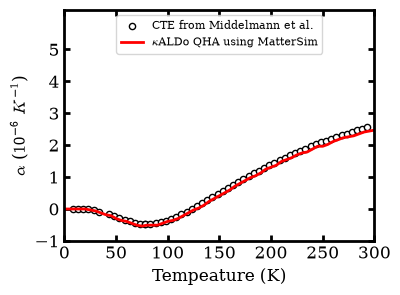

In [4]:
# Initalize temperature array and low in thermal expansion coefficients
temperature = np.linspace(0, 1800, 361)
coefficients_of_thermal_expansions = np.load('kaldo_runs/alpha_T.npy', allow_pickle=True)
lattice = np.load('kaldo_runs/L_T.npy', allow_pickle=True)
free_energies = np.load('kaldo_runs/F_T.npy', allow_pickle=True)

# Tabluate experimental data
tempature_exp = np.array([8.15, 13.15, 18.15, 23.15, 28.15,
                          33.15, 43.15, 48.15, 53.15, 58.15,
                          63.15, 68.15, 73.15, 78.15, 78.15, 
                         83.15, 88.15, 93.15, 98.15, 103.15,
                         108.15, 113.15, 118.15, 123.15, 128.15,
                         133.15, 138.15, 143.15, 148.15, 153.15,
                         158.15, 163.15, 168.15, 173.15, 178.15,
                         183.15, 188.15, 193.15, 198.15, 203.15,
                         208.15, 213.15, 218.15, 223.15, 228.15,
                         233.15, 238.15, 243.15, 248.15, 253.15,
                         258.15, 263.15, 268.15, 273.15, 278.15,
                         283.15, 288.15, 293.15])

alpha_exp = np.array([0.0, -0.1, -2.0, -13.1, -40.9,
                      -86.2, -144.0, -207.19, -271.9, -331.7,
                      -383.7, -425.5, -455.5, -472.6, -476.2,
                      -466.5, -443.8, -409.0, -363.0, -306.9,
                     -242.1, -169.6, -90.8, -6.8, 81.4,
                      172.8, 266.4, 361.7, 457.7, 554.0,
                     650.1, 745.5, 839.9, 932.9, 1024.4,
                     1114.1, 1201.9, 1287.6, 1371.2, 1452.6,
                     1531.7, 1608.6, 1683.3, 1755.7, 1825.9,
                     1893.9, 1959.7, 2023.5, 2085.1, 2144.8, 
                     2202.4, 2258.2, 2312.2, 2364.3, 2414.7,
                     2463.4, 2510.5, 2556.1]) / 1000.0

fig = figure(figsize=(4,3))
set_fig_properties([gca()])
scatter(tempature_exp, alpha_exp, edgecolor='k', facecolor='w', marker='o', s=20, zorder=1, label='CTE from Middelmann et al.')
plot(temperature, 1e6 * coefficients_of_thermal_expansions, 'r-', lw=2, label=r'$\kappa$ALDo QHA using MatterSim')
legend(loc='upper center', fontsize=8)
gca().set_xticks(np.arange(0, 2100, 50))
gca().set_yticks(np.arange(-1, 6, 1))
xlabel('Tempeature (K)')
ylabel(r'$\alpha$ ($10^{-6} \ K^{-1}$)')
xlim([0, 300])
show()

## Plot thermal expansion ($\alpha$), lattice constants $\&$ free energies

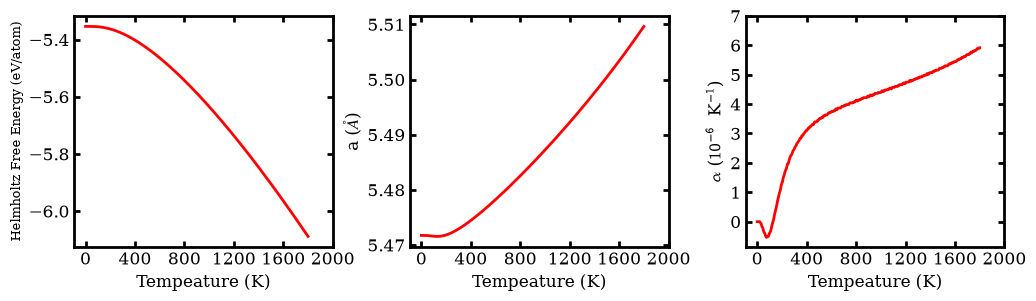

In [5]:
fig = figure(figsize=(12,3))

subplot(1,3,1)
set_fig_properties([gca()])
plot(temperature, free_energies/1000, 'r-', lw=2)
gca().set_xticks(np.arange(0, 2400, 400))
xlabel('Tempeature (K)')
ylabel(r"Helmholtz Free Energy (eV/atom)", fontsize=9)


subplot(1,3,2)
set_fig_properties([gca()])
plot(temperature, lattice, 'r-', lw=2)
gca().set_xticks(np.arange(0, 2400, 400))
xlabel('Tempeature (K)')
ylabel(r'a ($\AA$)')

subplot(1,3,3)
set_fig_properties([gca()])
plot(temperature, 1e6 * coefficients_of_thermal_expansions, 'r-', lw=2)
gca().set_yticks(np.arange(0, 8, 1))
gca().set_xticks(np.arange(0, 2400, 400))
xlabel('Tempeature (K)')
ylabel(r'$\alpha$ ($10^{-6}$  K$^{-1}$)')
subplots_adjust(hspace=0, wspace=0.3)
show()